In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/multiclassificationtask/sample_submission.csv
/kaggle/input/competitions/multiclassificationtask/train.csv
/kaggle/input/competitions/multiclassificationtask/test.csv


In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
import sklearn as sk
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
import time

In [3]:
input_path = '/kaggle/input/competitions/multiclassificationtask/'
train = pd.read_csv(input_path + 'train.csv')
test = pd.read_csv(input_path + 'test.csv')

print(f"Train: {train.shape}")
print(f"Test: {test.shape}")

Train: (15000, 20)
Test: (10000, 19)


In [4]:
train

,id,N_Days,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Status
0,0,2178.0,D-penicillamine,16374.0,F,N,N,N,N,0.5,263.0,3.20,43.0,1110.0,106.95,67.0,430.0,9.6,3.0,C
1,1,2644.0,D-penicillamine,17774.0,F,N,N,N,N,0.8,280.0,3.60,22.0,678.0,62.00,80.0,427.0,13.0,3.0,C
2,2,3069.0,Placebo,17844.0,F,N,N,N,N,1.1,408.0,4.40,54.0,2108.0,142.60,137.0,203.0,10.6,3.0,C
3,3,2216.0,Placebo,19221.0,F,N,Y,Y,N,0.8,252.0,3.70,36.0,843.0,55.80,56.0,336.0,9.6,4.0,C
4,4,2256.0,Placebo,21600.0,F,N,N,N,N,4.7,348.0,3.06,464.0,961.0,120.90,146.0,298.0,11.0,2.0,D
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,14995,1783.0,Placebo,23107.0,F,N,Y,N,S,1.3,243.0,3.76,58.0,944.0,97.00,93.0,233.0,9.9,4.0,C
14996,14996,3492.0,NaN,13149.0,F,NaN,NaN,NaN,N,0.7,NaN,4.03,NaN,NaN,NaN,NaN,273.0,10.3,2.0,C
14997,14997,1170.0,NaN,22646.0,F,NaN,NaN,NaN,N,0.8,NaN,3.14,NaN,NaN,NaN,NaN,280.0,10.6,3.0,C
14998,14998,1433.0,Placebo,21828.0,F,N,N,N,N,0.6,280.0,4.04,52.0,843.0,28.38,189.0,334.0,10.0,2.0,C


In [5]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             15000 non-null  int64  
 1   N_Days         15000 non-null  float64
 2   Drug           8494 non-null   object 
 3   Age            15000 non-null  float64
 4   Sex            15000 non-null  object 
 5   Ascites        8502 non-null   object 
 6   Hepatomegaly   8492 non-null   object 
 7   Spiders        8491 non-null   object 
 8   Edema          15000 non-null  object 
 9   Bilirubin      15000 non-null  float64
 10  Cholesterol    6701 non-null   float64
 11  Albumin        15000 non-null  float64
 12  Copper         8399 non-null   float64
 13  Alk_Phos       8488 non-null   float64
 14  SGOT           8486 non-null   float64
 15  Tryglicerides  6666 non-null   float64
 16  Platelets      14436 non-null  float64
 17  Prothrombin    14984 non-null  float64
 18  Stage 

In [6]:
train.describe()

,id,N_Days,Age,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
count,15000.000000,15000.000000,15000.000000,15000.000000,6701.000000,15000.000000,8399.000000,8488.000000,8486.000000,6666.000000,14436.000000,14984.000000,15000.000000
mean,7499.500000,1971.721267,19298.658267,1.845433,329.177302,3.526103,75.647339,1618.598233,106.483631,111.387886,252.917983,10.626111,3.024800
std,4330.271354,1333.733576,3797.580260,2.674859,180.320802,0.372268,74.830472,1767.240078,57.206017,55.056133,94.049175,0.731416,0.871303
min,0.000000,3.000000,400.000000,0.200000,120.000000,0.500000,2.000000,3.400000,0.900000,19.000000,32.000000,9.000000,1.000000
25%,3749.750000,1095.000000,16658.000000,0.600000,242.000000,3.290000,31.000000,720.000000,71.000000,80.000000,181.000000,10.100000,2.000000
50%,7499.500000,1786.000000,19544.000000,0.900000,280.000000,3.580000,52.000000,1072.000000,97.650000,99.000000,248.000000,10.600000,3.000000
75%,11249.250000,2635.000000,22347.000000,1.800000,364.000000,3.770000,89.000000,1664.000000,130.200000,133.000000,311.000000,11.000000,4.000000
max,14999.000000,38320.000000,129398.000000,28.000000,2078.000000,4.640000,662.000000,13862.400000,2653.000000,1669.000000,1024.000000,18.000000,4.000000


In [7]:
import os

# Papkadagi barcha fayllar
print(os.listdir(input_path))

sample = pd.read_csv(input_path + 'sample_submission.csv')
sample.head()

['sample_submission.csv', 'train.csv', 'test.csv']


,id,Status_C,Status_CL,Status_D
0,15000,0.628084,0.034788,0.337128
1,15001,0.628084,0.034788,0.337128
2,15002,0.628084,0.034788,0.337128
3,15003,0.628084,0.034788,0.337128
4,15004,0.628084,0.034788,0.337128


In [8]:
def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    chi2 = chi2_contingency(ct)[0]
    n = ct.values.sum()
    r, k = ct.shape
    phi2 = chi2 / n
    phi2c = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rc = r - ((r-1)**2)/(n-1)
    kc = k - ((k-1)**2)/(n-1)
    denom = min(kc-1, rc-1)
    if denom <= 0:          # bitta toifali ustun uchun himoya
        return 0.0
    return np.sqrt(phi2c / denom)

Hepatomegaly     0.435
Copper           0.363
N_Days           0.360
Bilirubin        0.351
Cholesterol      0.350
Spiders          0.344
Tryglicerides    0.337
SGOT             0.335
Prothrombin      0.327
Ascites          0.325
Platelets        0.318
Alk_Phos         0.316
Age              0.301
Stage            0.252
Edema            0.214
Albumin          0.211
Sex              0.115
Drug             0.042
id               0.000
dtype: float64


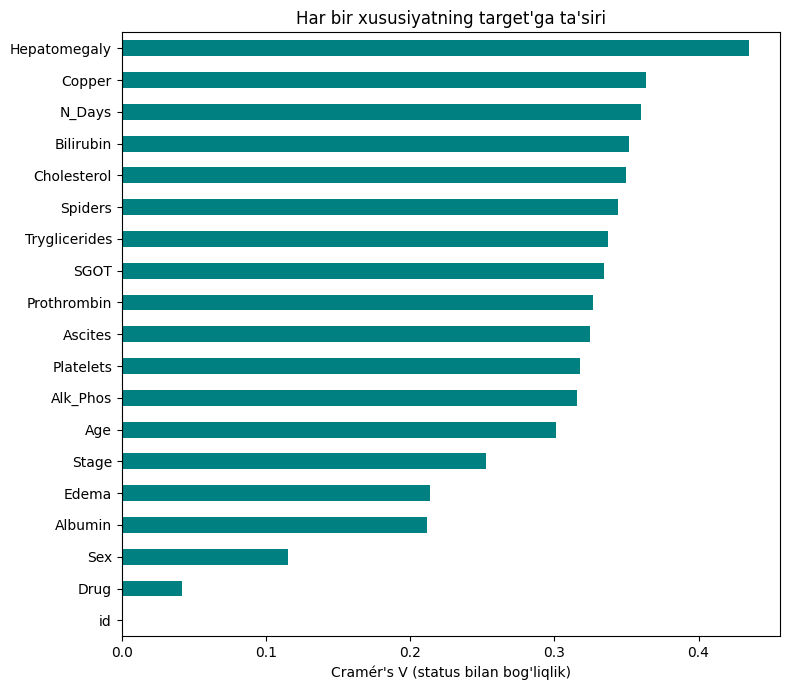

In [9]:
scores = (train.drop(columns='Status')
            .apply(lambda col: cramers_v(col, train['Status']))
            .sort_values(ascending=False))

print(scores.round(3))

plt.figure(figsize=(8, 7))
scores.sort_values().plot(kind='barh', color='teal')
plt.xlabel("Cramér's V (status bilan bog'liqlik)")
plt.title("Har bir xususiyatning target'ga ta'siri")
plt.tight_layout()
plt.show()

In [10]:
le = LabelEncoder()
y = le.fit_transform(train["Status"])        # C→0, CL→1, D→2
X = train.drop(columns=["id", "Status"])     # id kerak emas

print(le.classes_)
print(train["Status"].value_counts(normalize=True))

['C' 'CL' 'D' 'Y']
Status
C     0.670200
D     0.304333
CL    0.025400
Y     0.000067
Name: proportion, dtype: float64


In [11]:
# Xato yorliqli qatorni ko'ramiz
print(train[train["Status"] == "Y"])

# Uni o'chirib, indeksni yangilaymiz
train = train[train["Status"] != "Y"].reset_index(drop=True)

le = LabelEncoder()
y = le.fit_transform(train["Status"])        # C→0, CL→1, D→2
X = train.drop(columns=["id", "Status"])
print(le.classes_)                           # ['C' 'CL' 'D'] bo'lishi kerak

          id  N_Days     Drug      Age Sex Ascites Hepatomegaly Spiders Edema  \
13789  13789  4127.0  Placebo  20555.0   F       Y            Y       Y     Y   

       Bilirubin  Cholesterol  Albumin  Copper  Alk_Phos   SGOT  \
13789        0.6        267.0     2.75    11.0    1273.0  72.85   

       Tryglicerides  Platelets  Prothrombin  Stage Status  
13789           49.0      156.0         13.0    4.0      Y  
['C' 'CL' 'D']


In [12]:
block = ["Drug", "Ascites", "Hepatomegaly", "Spiders", "Copper", "Alk_Phos", "SGOT"]

# Har qatorda shu 7 ustundan nechtasi bo'sh
print(train[block].isna().sum(axis=1).value_counts().sort_index())

0    8388
1      94
2       1
3       2
5       3
6      46
7    6465
Name: count, dtype: int64


In [13]:
for col in ["Drug", "Cholesterol", "Platelets"]:
    print(f"--- {col} bo'shmi? ---")
    print(pd.crosstab(train[col].isna(), train["Status"], normalize="index").round(3), "\n")

--- Drug bo'shmi? ---
Status      C     CL      D
Drug                       
False   0.675  0.026  0.298
True    0.664  0.024  0.312 

--- Cholesterol bo'shmi? ---
Status           C     CL      D
Cholesterol                     
False        0.683  0.030  0.287
True         0.660  0.022  0.318 

--- Platelets bo'shmi? ---
Status         C     CL      D
Platelets                     
False      0.672  0.026  0.302
True       0.619  0.018  0.363 



In [14]:
# Train va test'da har ustunning bo'sh foizi yonma-yon
miss = pd.DataFrame({
    "train_%": train.isna().mean().mul(100).round(1),
    "test_%":  test.isna().mean().mul(100).round(1),
})
print(miss[miss.sum(axis=1) > 0])

               train_%  test_%
Alk_Phos          43.4    44.0
Ascites           43.3    43.9
Cholesterol       55.3    56.5
Copper            44.0    44.7
Drug              43.4    44.0
Hepatomegaly      43.4    44.0
Platelets          3.8     3.8
Prothrombin        0.1     0.1
SGOT              43.4    44.1
Spiders           43.4    44.0
Tryglicerides     55.6    56.8


In [15]:
cat_cols = ["Drug", "Sex", "Ascites", "Hepatomegaly", "Spiders", "Edema"]
num_cols = [c for c in X.columns if c not in cat_cols]

# Train: kategorik NaN → "Unknown"
X = X.copy()
X[cat_cols] = X[cat_cols].fillna("Unknown")

# Test: xuddi shu ishlov
X_test = test.drop(columns=["id"]).copy()
X_test[cat_cols] = X_test[cat_cols].fillna("Unknown")

print(num_cols)

['N_Days', 'Age', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin', 'Stage']


In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Sonli ustunlar: median + "bo'sh edi" indikatori → skaylash
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler",  StandardScaler()),
])

preprocess = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

logreg = Pipeline([
    ("prep",  preprocess),
    ("model", LogisticRegression(max_iter=2000)),   # class_weight YO'Q — log loss uchun
])

# neg_log_loss manfiy qaytaradi, minus bilan musbat qilamiz
scores = -cross_val_score(logreg, X, y, cv=cv, scoring="neg_log_loss")
print(f"LogReg log loss: {scores.mean():.4f} ± {scores.std():.4f}")

LogReg log loss: 0.4615 ± 0.0124


In [17]:
import lightgbm as lgb

# Kategoriklarni category turiga o'tkazamiz (test — train kategoriyalari bilan)
X_lgb, X_test_lgb = X.copy(), X_test.copy()
for c in cat_cols:
    X_lgb[c] = X_lgb[c].astype("category")
    X_test_lgb[c] = pd.Categorical(X_test_lgb[c], categories=X_lgb[c].cat.categories)

lgbm = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.03,
    num_leaves=15,              # kichik daraxt — overfitting'ga qarshi
    min_child_samples=30,
    subsample=0.8, subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=42,
    verbose=-1,
)

scores = -cross_val_score(lgbm, X_lgb, y, cv=cv, scoring="neg_log_loss")
print(f"LightGBM log loss: {scores.mean():.4f} ± {scores.std():.4f}")

LightGBM log loss: 0.3733 ± 0.0084


In [18]:
# Butun train'da yakuniy model
lgbm.fit(X_lgb, y)
proba = lgbm.predict_proba(X_test_lgb)          # ustunlar: C, CL, D

submission = pd.DataFrame({
    "id":        test["id"],
    "Status_C":  proba[:, 0],
    "Status_CL": proba[:, 1],
    "Status_D":  proba[:, 2],
})
submission.to_csv("submission.csv", index=False)

# Tekshiruv: shakl, qator yig'indilari, id'lar sample bilan mos
print(submission.shape)                                  # (10000, 4)
print(proba.sum(axis=1).min(), proba.sum(axis=1).max())  # ikkalasi ≈ 1.0
print((submission["id"].values == sample["id"].values).all())
submission.head()

(10000, 4)
0.9999999999999997 1.0000000000000002
True


,id,Status_C,Status_CL,Status_D
0,15000,0.386448,0.004425,0.609127
1,15001,0.849325,0.011767,0.138908
2,15002,0.695744,0.007591,0.296665
3,15003,0.987127,0.000828,0.012045
4,15004,0.216525,0.116334,0.667142


In [19]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import log_loss, accuracy_score

# Har qatorga — uni ko'rmagan modeldan ehtimol
oof_lgb = cross_val_predict(lgbm, X_lgb, y, cv=cv, method="predict_proba")

# Baseline: hamma qatorga train'dagi sinf ulushlari
prior = np.bincount(y) / len(y)
baseline = log_loss(y, np.tile(prior, (len(y), 1)))
ll = log_loss(y, oof_lgb)

# Har qatorda haqiqiy sinfga berilgan ehtimol
p_true = oof_lgb[np.arange(len(y)), y]

print(f"Baseline log loss : {baseline:.4f}")
print(f"LightGBM log loss : {ll:.4f}  ({(1 - ll / baseline) * 100:.0f}% yaxshiroq)")
print(f"Haqiqiy sinfga o'rtacha ehtimol: {np.exp(-ll):.3f}")
print(f"Accuracy (eng katta ehtimol bo'yicha): {accuracy_score(y, oof_lgb.argmax(1)):.3f}")

Baseline log loss : 0.7235
LightGBM log loss : 0.3733  (48% yaxshiroq)
Haqiqiy sinfga o'rtacha ehtimol: 0.688
Accuracy (eng katta ehtimol bo'yicha): 0.855


     soni  o'rtacha loss  loss ulushi %    AUC
C   10053          0.201         36.038  0.924
CL    381          2.560         17.418  0.894
D    4565          0.571         46.544  0.927


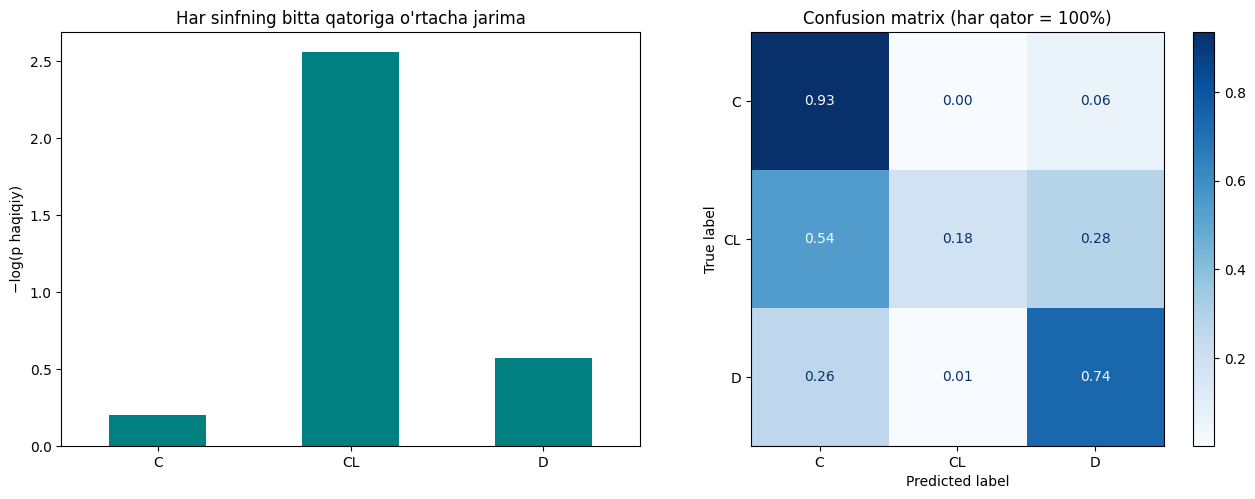

In [20]:
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay

classes = le.classes_                                   # ['C', 'CL', 'D']
row_loss = -np.log(np.clip(p_true, 1e-15, 1))           # har qatorning jarimasi

summary = pd.DataFrame({
    "soni":            [(y == k).sum() for k in range(3)],
    "o'rtacha loss":   [row_loss[y == k].mean() for k in range(3)],
    "loss ulushi %":   [row_loss[y == k].sum() / row_loss.sum() * 100 for k in range(3)],
    "AUC":             [roc_auc_score((y == k).astype(int), oof_lgb[:, k]) for k in range(3)],
}, index=classes).round(3)
print(summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

summary["o'rtacha loss"].plot(kind="bar", ax=axes[0], color="teal")
axes[0].set_title("Har sinfning bitta qatoriga o'rtacha jarima")
axes[0].set_ylabel("−log(p haqiqiy)")
axes[0].tick_params(axis="x", rotation=0)

ConfusionMatrixDisplay.from_predictions(
    y, oof_lgb.argmax(1), display_labels=classes,
    normalize="true", values_format=".2f", cmap="Blues", ax=axes[1])
axes[1].set_title("Confusion matrix (har qator = 100%)")

plt.tight_layout()
plt.show()

C eng yaxshi bashorat qilingan sinf. 93% to'g'ri topilgan, AUC 0.924.
D asosiy xato manbai. 26% i C deb bashorat qilingan, umumiy loss'ning 46.5% i shu sinfdan keladi.
CL bitta qatorga jarima eng katta (2.56), chunki sinf juda kam (2.5%). Lekin AUC 0.894, ya'ni model bu bemorlarni boshqalardan yaxshi ajrata oladi.

Qisqa xulosa: Statusni value count qilganimizda 4 ta turi chiqdi. Bir dona Y status qo'shilib qolgan ekan uni o'chirdik.
Nega LightGMB modelini tanladik: Sababi LogRegda yaxshi natija berdi. Log reg: 0.46 LightGBM 0.37 loss berdi.
LightGBM bo'sh ya'ni nan qiymatlar bilan o'zi ishlagani uchun ham osonroq bo'ldi, deyarli 50% bo'sh ustunlarni to'ldirmasdan ishlatdi
Yana eng muhimi LightGBM Belgilar orasidagi nochiziqli bog'liqliklarni ushlaydi va outlier'larga chidamli ekani